# AI task 2

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score


In [2]:
# Task 1: Dataset Loading & Initial View
df = sns.load_dataset('titanic')
print("Shape:", df.shape)
print("First 7 rows:\n", df.head(7))

Shape: (891, 15)
First 7 rows:
    survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   
5         0       3    male   NaN      0      0   8.4583        Q  Third   
6         0       1    male  54.0      0      0  51.8625        S  First   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  
5    man        True  NaN   Queenst

In [3]:
# Task 2: Data Exploration
print("Descriptive Stats:\n", df.describe())
print("Numerical Columns:", df.select_dtypes(include=['int64', 'float64']).columns.tolist())
print("Categorical Columns:", df.select_dtypes(include=['object']).columns.tolist())
print("Sex Distribution:\n", df['sex'].value_counts())

Descriptive Stats:
          survived      pclass         age       sibsp       parch        fare
count  891.000000  891.000000  714.000000  891.000000  891.000000  891.000000
mean     0.383838    2.308642   29.699118    0.523008    0.381594   32.204208
std      0.486592    0.836071   14.526497    1.102743    0.806057   49.693429
min      0.000000    1.000000    0.420000    0.000000    0.000000    0.000000
25%      0.000000    2.000000   20.125000    0.000000    0.000000    7.910400
50%      0.000000    3.000000   28.000000    0.000000    0.000000   14.454200
75%      1.000000    3.000000   38.000000    1.000000    0.000000   31.000000
max      1.000000    3.000000   80.000000    8.000000    6.000000  512.329200
Numerical Columns: ['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']
Categorical Columns: ['sex', 'embarked', 'who', 'embark_town', 'alive']
Sex Distribution:
 sex
male      577
female    314
Name: count, dtype: int64


C:\Users\hamza\AppData\Local\Temp\ipykernel_14900\777762338.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print("Categorical Columns:", df.select_dtypes(include=['object']).columns.tolist())


In [9]:
# Task 3: Data Cleaning
print("Missing Values:\n", df.isnull().sum())
df['age'].fillna(df['age'].median(), inplace=True)
df['fare'].fillna(df['fare'].median(), inplace=True)
df['embarked'].fillna(df['embarked'].mode()[0], inplace=True)
if 'Cabin' in df.columns:
    df.drop(columns=['Cabin'], inplace=True)


Missing Values:
 survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64


C:\Users\hamza\AppData\Local\Temp\ipykernel_14900\2746764361.py:3: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df['age'].fillna(df['age'].median(), inplace=True)
C:\Users\hamza\AppData\Local\Temp\ipykernel_14900\2746764361.py:4: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignme

In [10]:
# Task 4: Feature Selection & SVC Model
le = LabelEncoder()
df['sex'] = le.fit_transform(df['sex'])
# Match the Titanic dataset's lowercase column names and handle missing values
df['age'] = df['age'].fillna(df['age'].median())
df['fare'] = df['fare'].fillna(df['fare'].median())
df['embarked'] = df['embarked'].fillna(df['embarked'].mode()[0])

# Encode embarked
df['embarked'] = le.fit_transform(df['embarked'])

# Create aliases expected by the existing code below
df['Pclass'] = df['pclass']
df['Age'] = df['age']
df['SibSp'] = df['sibsp']
df['Parch'] = df['parch']
df['Fare'] = df['fare']
df['Survived'] = df['survived']

features = ['Pclass', 'sex', 'Age', 'SibSp', 'Parch', 'Fare', 'embarked']
X = df[features]
y = df['Survived']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = SVC(kernel='rbf', random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1-Score:", f1_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))


Accuracy: 0.8156424581005587
Precision: 0.8153846153846154
Recall: 0.7162162162162162
F1-Score: 0.762589928057554
Confusion Matrix:
 [[93 12]
 [21 53]]


<Axes: xlabel='Pclass', ylabel='Survived'>

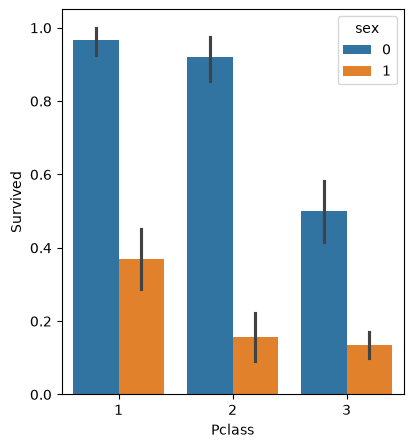

In [26]:

# Task 5: Visualizations
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
sns.barplot(data=df, x='Pclass', y='Survived', hue='sex')


<Axes: xlabel='fare', ylabel='Count'>

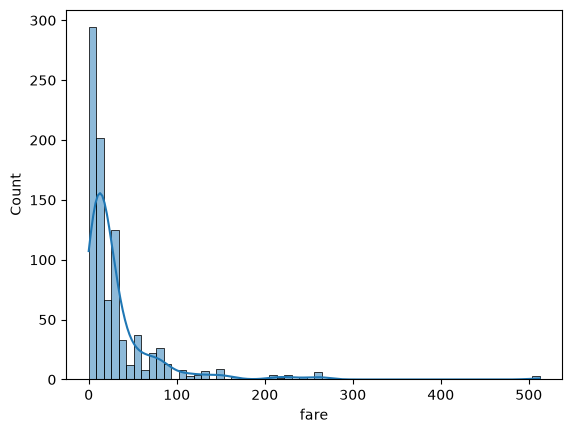

In [21]:
plt.subplot(1, 1, 1)
sns.histplot(df['fare'], kde=True)


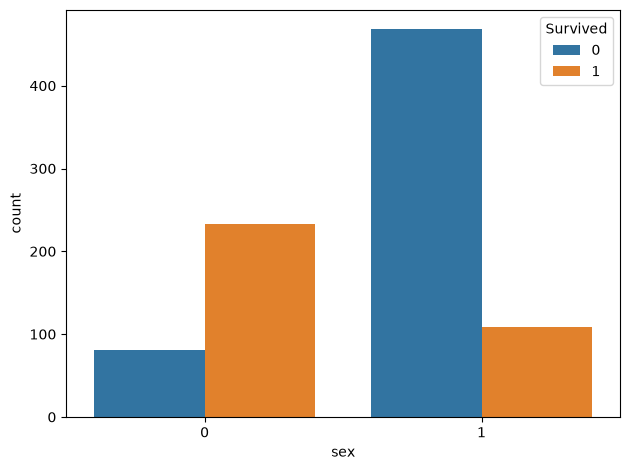

In [20]:
plt.subplot(1, 1, 1)
sns.countplot(data=df, x='sex', hue='Survived')
plt.tight_layout()
plt.show()